# M3.3 · 模型可解释性（自实现）

> 黑盒模型需要解释：哪些特征在驱动预测？特征如何影响预测？
> 本节不依赖 shap，用三种可解释工具：分裂重要性、排列重要性、部分依赖（PDP）。

## 一、三种可解释工具

| 工具 | 原理 | 特点 |
|---|---|---|
| 分裂重要性 | 树分裂带来的增益累计 | 快，但偏向高基数/高共线特征 |
| 排列重要性 | 打乱某列后打分下降 | 模型无关、更可信，成本高 |
| 部分依赖 PDP | 固定特征取网格值看平均预测 | 刻画边际效应与方向 |

**重点**：分裂重要性会高估高基数和共线特征，排列重要性更可靠，两者排序常不一致。


## 二、构造建模数据并训练

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import hfactors
from factor_lab2.combine import cross_zscore
from model_lab2 import labels, interpret
import lightgbm as lgb
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
hi=raw['$high'].unstack('instrument'); lo=raw['$low'].unstack('instrument')
vo=raw['$volume'].unstack('instrument')
lab = labels.cs_rank_label(cl, 5)
hf = hfactors.build_hf_factors(op, cl, hi, lo, vo)
feat_names = ['已实现波动20','日内动量20','尾盘位置20','量价相关20','收益偏度60']
z = pd.concat({n: cross_zscore(hf[n]).stack() for n in feat_names}, axis=1)
z.index.names = ['datetime','instrument']
df = z.join(lab.stack().rename('y')).dropna()
cut = df.index.get_level_values('datetime').unique()
split = cut[int(len(cut)*0.8)]
tr = df[df.index.get_level_values('datetime') <= split]
te = df[df.index.get_level_values('datetime') > split]
model = lgb.LGBMRegressor(n_estimators=150, num_leaves=31, learning_rate=0.05,
                          random_state=42, verbose=-1)
model.fit(tr[feat_names], tr['y'])
print('训练/测试:', tr.shape, te.shape)

[17928:MainThread](2026-10-31 09:41:48,102) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[17928:MainThread](2026-10-31 09:41:49,986) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[17928:MainThread](2026-10-31 09:41:49,988) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


训练/测试: (417073, 6) (122511, 6)


## 三、分裂重要性 vs 排列重要性

In [2]:
fi = interpret.model_feature_importance(model, feat_names)
print('分裂重要性:')
print(fi.round(2).to_string())
te_s = te.sample(2000, random_state=42)
def score_fn(m, X, y):
    return pd.Series(m.predict(X)).corr(pd.Series(np.asarray(y)),
                                        method='spearman')
pi = interpret.permutation_importance(model, te_s[feat_names], te_s['y'],
                                      score_fn, n_repeat=2)
print('\n排列重要性:')
print(pi.round(4).to_string())

分裂重要性:
已实现波动20    1043
收益偏度60     1039
量价相关20      970
尾盘位置20      726
日内动量20      722

排列重要性:
量价相关20     0.0458
收益偏度60     0.0130
日内动量20     0.0069
尾盘位置20     0.0001
已实现波动20   -0.0070


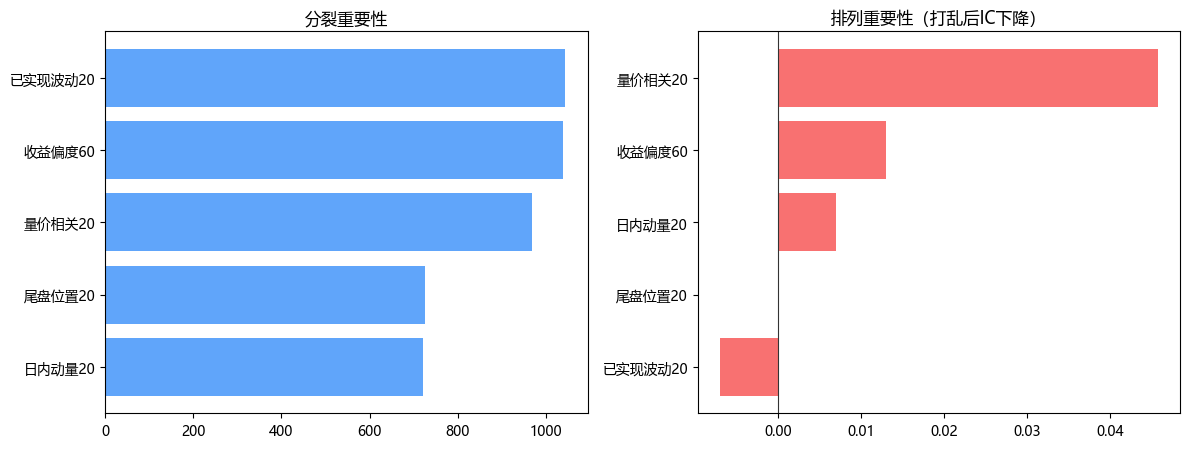

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(1,2, figsize=(12,4.6))
axes[0].barh(fi.index[::-1], fi.values[::-1], color='#60a5fa')
axes[0].set_title('分裂重要性')
axes[1].barh(pi.index[::-1], pi.values[::-1], color='#f87171')
axes[1].set_title('排列重要性（打乱后IC下降）')
axes[1].axvline(0, color='#333', lw=0.8)
plt.tight_layout(); plt.show()

## 四、部分依赖（PDP）

In [4]:
pdp0 = interpret.partial_dependence(model, te[feat_names], feat_names[0])
pdp1 = interpret.partial_dependence(model, te[feat_names], feat_names[3])
print('PDP %s: 首末 %.3f -> %.3f' % (feat_names[0], pdp0.iloc[0], pdp0.iloc[-1]))
print('PDP %s: 首末 %.3f -> %.3f' % (feat_names[3], pdp1.iloc[0], pdp1.iloc[-1]))

PDP 已实现波动20: 首末 0.005 -> 0.016
PDP 量价相关20: 首末 -0.020 -> 0.025


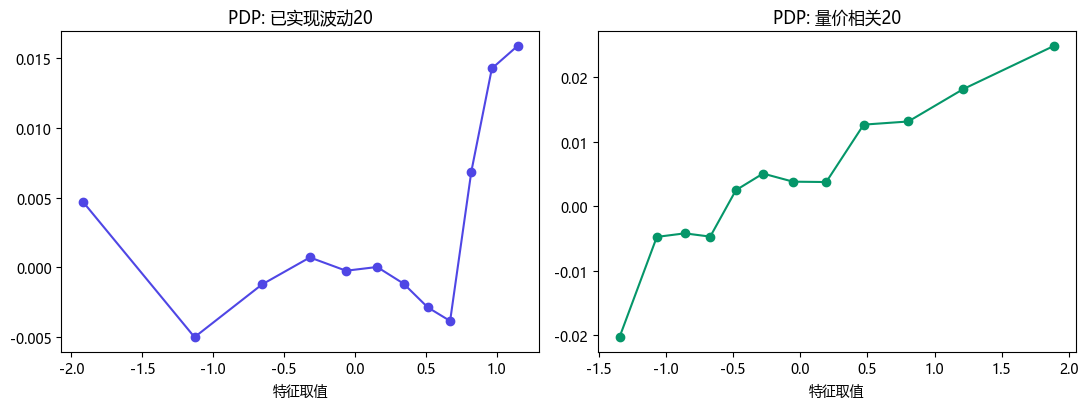

In [5]:
fig, axes = plt.subplots(1,2, figsize=(11,4.2))
axes[0].plot(pdp0.index, pdp0.values, marker='o', color='#4f46e5')
axes[0].set_title('PDP: '+feat_names[0]); axes[0].set_xlabel('特征取值')
axes[1].plot(pdp1.index, pdp1.values, marker='o', color='#059669')
axes[1].set_title('PDP: '+feat_names[3]); axes[1].set_xlabel('特征取值')
plt.tight_layout(); plt.show()

## 五、小结与面试要点

**面试高频：**
- 分裂重要性有什么缺陷？（答：偏向高基数/高共线特征，依赖训练集，不能反映因果）
- 排列重要性原理？（答：打乱某特征破坏其信息，看性能下降，模型无关、更可信）
- PDP 是什么？（答：固定特征取网格值、其余不变，看平均预测的边际效应）
- 重要性能当因果吗？（答：不能，只反映预测依赖，可能是相关或共线）
- 排列重要性的注意点？（答：强相关特征单独打乱会产生不现实样本，可考虑成组打乱）

## 动手练习
1. 训练模型并输出分裂重要性；
2. 实现排列重要性并与分裂重要性对比；
3. 画两个特征的 PDP 并解释方向。

---
下一节 M3.4 排序学习（ranker）与 NDCG。